BÀI 6 – TRANG 45: SO SÁNH THUẬT TOÁN APRIORI VÀ FP-GROWTH
Yêu cầu: Sử dụng bộ dữ liệu Groceries gồm 9.835 giao dịch và 169 mặt hàng để tìm các tập phổ biến và so sánh thời gian xử lý giữa hai thuật toán.

Thực hiện theo đúng 3 câu a, b, c trong tài liệu LAB1.

Chuẩn bị: Import thư viện và đọc dữ liệu Groceries

In [1]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import csv

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

print("Phạm Lê Anh Khoa - 6451071035")


with open('data/groceries.csv', 'r', encoding='utf-8-sig') as f:
    reader = csv.reader(f)
    transactions = [
        [item.strip() for item in row if item.strip()]
        for row in reader
        if row
    ]

print("Số giao dịch:", len(transactions))
print("5 giao dịch đầu tiên:")

for transaction in transactions[:5]:
    print(transaction)


Phạm Lê Anh Khoa - 6451071035
Số giao dịch: 9835
5 giao dịch đầu tiên:
['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
['tropical fruit', 'yogurt', 'coffee']
['whole milk']
['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']


Chuyển dữ liệu về dạng One-hot Encoding

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")

te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

df_encoded = pd.DataFrame(
    te_array,
    columns=te.columns_
)

print("Kích thước dữ liệu:", df_encoded.shape)

df_encoded.head(10)


Phạm Lê Anh Khoa - 6451071035
Kích thước dữ liệu: (9835, 169)


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
5,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


Câu a) Tìm tất cả các tập phổ biến bằng thuật toán Apriori với min_sup từ 0.01% đến 0.1% và ghi nhận thời gian xử lý

In [3]:

print("Phạm Lê Anh Khoa - 6451071035")

min_supports = [
    0.00025,
    0.0005,
    0.00075,
    0.001
]

apriori_times = []
apriori_counts = []

for min_sup in min_supports:
    start_time = time.perf_counter()

    frequent_itemsets = apriori(
        df_encoded,
        min_support=min_sup,
        use_colnames=True,
        low_memory=True
    )

    end_time = time.perf_counter()

    execution_time = end_time - start_time

    apriori_times.append(execution_time)
    apriori_counts.append(len(frequent_itemsets))

    print(f"Min Support: {min_sup * 100:.4f}%")
    print(f"Số tập phổ biến: {len(frequent_itemsets)}")
    print(f"Thời gian xử lý: {execution_time:.4f} giây")
    print("-" * 40)


Phạm Lê Anh Khoa - 6451071035
Min Support: 0.0250%
Số tập phổ biến: 166682
Thời gian xử lý: 78.1091 giây
----------------------------------------
Min Support: 0.0500%
Số tập phổ biến: 49580
Thời gian xử lý: 8.8858 giây
----------------------------------------
Min Support: 0.0750%
Số tập phổ biến: 19979
Thời gian xử lý: 2.7134 giây
----------------------------------------
Min Support: 0.1000%
Số tập phổ biến: 13492
Thời gian xử lý: 1.6730 giây
----------------------------------------


Hiển thị bảng kết quả Apriori

In [4]:
print("Phạm Lê Anh Khoa - 6451071035")

apriori_results = pd.DataFrame({
    'Min Support (%)': [x * 100 for x in min_supports],
    'Số tập phổ biến': apriori_counts,
    'Thời gian (giây)': apriori_times
})

apriori_results


Phạm Lê Anh Khoa - 6451071035


,Min Support (%),Số tập phổ biến,Thời gian (giây)
0,0.025,166682,78.109141
1,0.050,49580,8.885826
2,0.075,19979,2.713441
3,0.100,13492,1.673029


Câu b) Tìm tất cả các tập phổ biến bằng thuật toán FP-Growth và ghi nhận thời gian xử lý

In [5]:
print("Phạm Lê Anh Khoa - 6451071035")

fpgrowth_times = []
fpgrowth_counts = []

for min_sup in min_supports:
    start_time = time.perf_counter()

    frequent_itemsets_fp = fpgrowth(
        df_encoded,
        min_support=min_sup,
        use_colnames=True
    )

    end_time = time.perf_counter()

    execution_time = end_time - start_time

    fpgrowth_times.append(execution_time)
    fpgrowth_counts.append(len(frequent_itemsets_fp))

    print(f"Min Support: {min_sup * 100:.4f}%")
    print(f"Số tập phổ biến: {len(frequent_itemsets_fp)}")
    print(f"Thời gian xử lý: {execution_time:.4f} giây")
    print("-" * 40)


Phạm Lê Anh Khoa - 6451071035
Min Support: 0.0250%
Số tập phổ biến: 166682
Thời gian xử lý: 6.0354 giây
----------------------------------------
Min Support: 0.0500%
Số tập phổ biến: 49580
Thời gian xử lý: 2.7115 giây
----------------------------------------
Min Support: 0.0750%
Số tập phổ biến: 19979
Thời gian xử lý: 1.3942 giây
----------------------------------------
Min Support: 0.1000%
Số tập phổ biến: 13492
Thời gian xử lý: 1.2046 giây
----------------------------------------


Hiển thị bảng kết quả FP-Growth

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")

fpgrowth_results = pd.DataFrame({
    'Min Support (%)': [x * 100 for x in min_supports],
    'Số tập phổ biến': fpgrowth_counts,
    'Thời gian (giây)': fpgrowth_times
})

fpgrowth_results


Phạm Lê Anh Khoa - 6451071035


,Min Support (%),Số tập phổ biến,Thời gian (giây)
0,0.025,166682,6.035381
1,0.050,49580,2.711511
2,0.075,19979,1.394235
3,0.100,13492,1.204613


Câu c) Vẽ biểu đồ so sánh thời gian xử lý của Apriori và FP-Growth

1. Tạo bảng so sánh kết quả hai thuật toán

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")

comparison = pd.DataFrame({
    'Min Support (%)': [x * 100 for x in min_supports],
    'Apriori (giây)': apriori_times,
    'FP-Growth (giây)': fpgrowth_times,
    'Số tập Apriori': apriori_counts,
    'Số tập FP-Growth': fpgrowth_counts
})

comparison


Phạm Lê Anh Khoa - 6451071035


,Min Support (%),Apriori (giây),FP-Growth (giây),Số tập Apriori,Số tập FP-Growth
0,0.025,78.109141,6.035381,166682,166682
1,0.050,8.885826,2.711511,49580,49580
2,0.075,2.713441,1.394235,19979,19979
3,0.100,1.673029,1.204613,13492,13492


2. Vẽ biểu đồ so sánh thời gian xử lý

Phạm Lê Anh Khoa - 6451071035


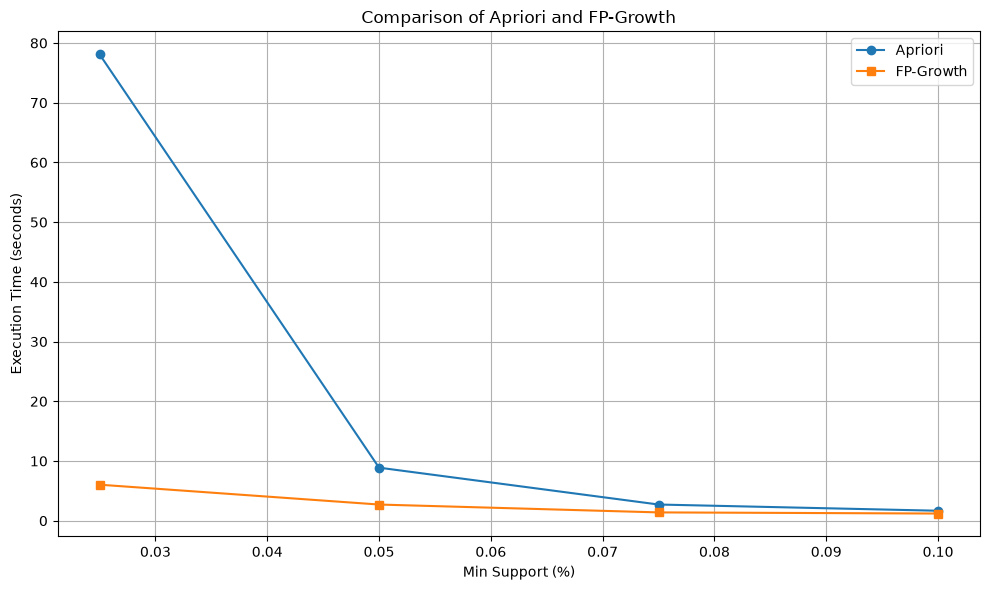

In [8]:
print("Phạm Lê Anh Khoa - 6451071035")

plt.figure(figsize=(10, 6))

plt.plot(
    comparison['Min Support (%)'],
    comparison['Apriori (giây)'],
    marker='o',
    label='Apriori'
)

plt.plot(
    comparison['Min Support (%)'],
    comparison['FP-Growth (giây)'],
    marker='s',
    label='FP-Growth'
)

plt.title('Comparison of Apriori and FP-Growth')
plt.xlabel('Min Support (%)')
plt.ylabel('Execution Time (seconds)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


3. Vẽ biểu đồ so sánh số lượng tập phổ biến

Phạm Lê Anh Khoa - 6451071035


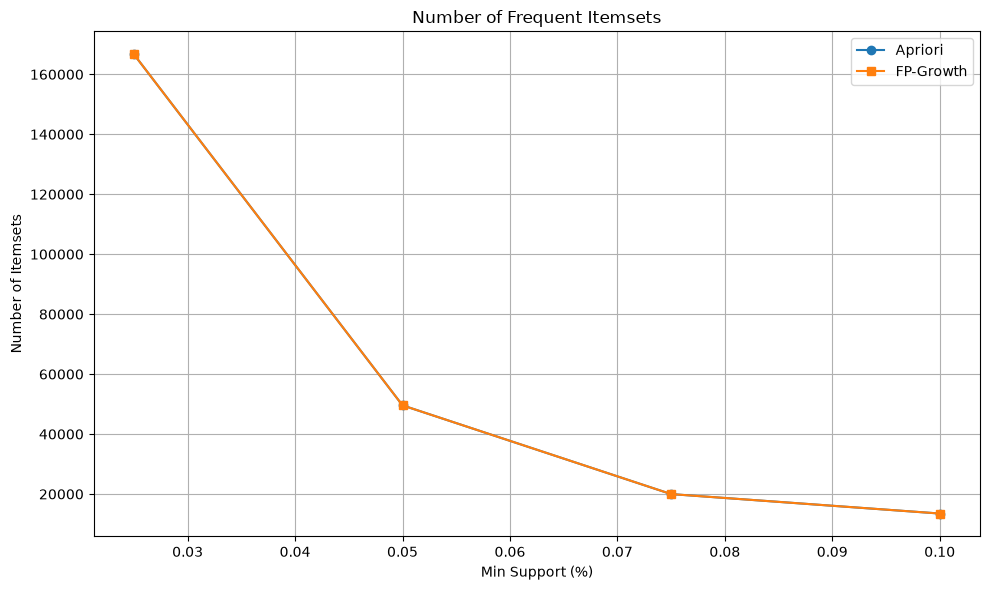

In [9]:
print("Phạm Lê Anh Khoa - 6451071035")

plt.figure(figsize=(10, 6))

plt.plot(
    comparison['Min Support (%)'],
    comparison['Số tập Apriori'],
    marker='o',
    label='Apriori'
)

plt.plot(
    comparison['Min Support (%)'],
    comparison['Số tập FP-Growth'],
    marker='s',
    label='FP-Growth'
)

plt.title('Number of Frequent Itemsets')
plt.xlabel('Min Support (%)')
plt.ylabel('Number of Itemsets')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


4. Kiểm tra hai thuật toán có tìm được cùng số tập phổ biến hay không

In [10]:
print("Phạm Lê Anh Khoa - 6451071035")

comparison['Kết quả khớp'] = (
    comparison['Số tập Apriori']
    == comparison['Số tập FP-Growth']
)

comparison


Phạm Lê Anh Khoa - 6451071035


,Min Support (%),Apriori (giây),FP-Growth (giây),Số tập Apriori,Số tập FP-Growth,Kết quả khớp
0,0.025,78.109141,6.035381,166682,166682,True
1,0.050,8.885826,2.711511,49580,49580,True
2,0.075,2.713441,1.394235,19979,19979,True
3,0.100,1.673029,1.204613,13492,13492,True
